# Práctica 2.3 — Detección de anomalías: los municipios que no se parecen a ningún otro

Este cuaderno acompaña la clase «Detección de anomalías» del tema 2.3. No hay etiquetas: nadie sabe de antemano cuáles municipios son anómalos. Se calcula un **puntaje de rareza** con cuatro métodos y, al final, se mide qué tanto encuentra cada uno con **errores de digitación sembrados a propósito**. Sigue el recorrido de la clase:

1. Datos · 2. **Una variable:** z y la caja · 3. **Varias variables:** Mahalanobis · 4. **Aislar:** Isolation Forest · 5. **Densidad local:** LOF · 6. Comparar los métodos · 7. Mapa · 8. **Evaluar con errores sembrados** · 9. Un puente con PCA

**Datos.** `datos/ej2_privaciones_ipm_2018.csv`: 1.122 municipios **reales**, con las 15 privaciones del IPM (índice de pobreza multidimensional) del DANE, censo 2018. Es la misma base de las prácticas de K-means y de componentes principales.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path
from scipy.stats import chi2
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EmpiricalCovariance
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

def encuadre(ax):
    """Encuadra el mapa en Colombia continental (San Andrés queda fuera del recuadro)."""
    ax.set_xlim(-79.3, -66.7); ax.set_ylim(-4.4, 12.6); ax.set_axis_off()

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

# Colores de los grupos, como en la clase: de azul (menos privación) a naranja (más), pasando por morado
MORADO = '#8a4fd1'
COL_G = [AZUL, MORADO, NARANJA]

## 1. Datos

In [3]:
df = pd.read_csv(DATOS / 'ej2_privaciones_ipm_2018.csv')
PRIV = list(df.columns[5:20])                     # las 15 privaciones del IPM
Z = StandardScaler().fit_transform(df[PRIV])      # escaladas: cada una con media 0 y desviación 1
N_REV = round(.03 * len(df))                      # el 3 % que se revisa
print(f'{len(df)} municipios, {len(PRIV)} privaciones; se revisará el 3 %: {N_REV} municipios')
df[['inasistencia_escolar', 'rezago_escolar', 'ipm']].describe().T

1122 municipios, 15 privaciones; se revisará el 3 %: 34 municipios


,count,mean,std,min,25%,50%,75%,max
inasistencia_escolar,"1,122.000",5.138,3.647,0.900,3.000,4.300,6.100,42.800
rezago_escolar,"1,122.000",19.040,7.700,5.300,13.825,17.300,22.400,62.100
ipm,"1,122.000",41.792,17.346,4.500,30.225,40.800,52.675,98.500


Se trabaja con las 15 privaciones escaladas (z) y se decide revisar el 3 % más raro: 34 municipios. La inasistencia escolar tiene una cola larga: la mediana es 4,3 %, pero el máximo llega a 42,8 %.

## 2. Una variable: z y la caja

z > 3 (más de 16.1 %): 22 municipios
Caja: Q1 = 3.0, Q3 = 6.1, IQR = 3.1; fuera del bigote (más de 10.8 %): 63 municipios


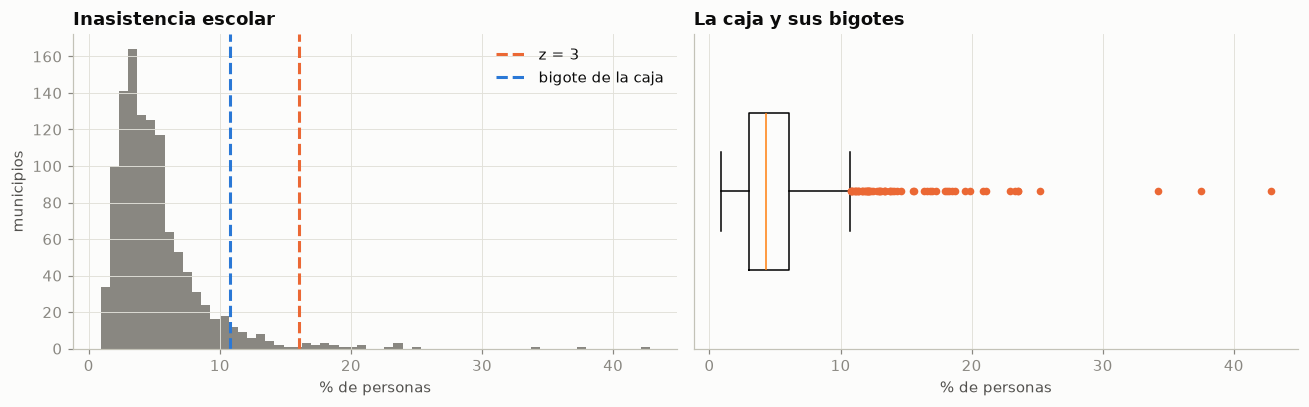

In [4]:
x = df.inasistencia_escolar
z = (x - x.mean()) / x.std(ddof=0)
q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1; bigote = q3 + 1.5 * iqr
print(f'z > 3 (más de {x.mean() + 3 * x.std(ddof=0):.1f} %): {(z > 3).sum()} municipios')
print(f'Caja: Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f}; fuera del bigote (más de {bigote:.1f} %): {(x > bigote).sum()} municipios')
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].hist(x, bins=60, color=GRIS); axs[0].axvline(x.mean() + 3 * x.std(ddof=0), color=NARANJA, ls='--', label='z = 3'); axs[0].axvline(bigote, color=AZUL, ls='--', label='bigote de la caja')
axs[0].set(title='Inasistencia escolar', xlabel='% de personas', ylabel='municipios'); axs[0].legend()
axs[1].boxplot(x, vert=False, widths=.5, flierprops=dict(markerfacecolor=NARANJA, markeredgecolor='none', markersize=5))
axs[1].set(title='La caja y sus bigotes', xlabel='% de personas', yticks=[])
plt.tight_layout(); plt.show()

Con la regla **z > 3** (más de 16,1 % de inasistencia) se señalan 22 municipios; con los **bigotes de la caja** (Q3 + 1,5 · IQR = 10,8 %), 63. La regla cambia el resultado: z supone una campana y, con una cola larga como esta, la desviación crece y deja pasar casos; la caja no se deja mover por los extremos. Sea cual sea la regla, hay que decir cuál se usó.

## 3. Varias variables: Mahalanobis

Un municipio puede ser raro por la **combinación** de sus valores. La distancia de Mahalanobis mide la distancia al centro teniendo en cuenta cómo se mueven juntas las variables.

In [5]:
# Mahalanobis con dos variables: rezago escolar e inasistencia escolar
D2 = ['rezago_escolar', 'inasistencia_escolar']
Z2 = StandardScaler().fit_transform(df[D2])
df['mah2'] = np.sqrt(EmpiricalCovariance().fit(Z2).mahalanobis(Z2))
df['euc2'] = np.hypot(Z2[:, 0], Z2[:, 1])
print(f'r = {np.corrcoef(Z2.T)[0, 1]:.3f}')
print(f'Fuera de la elipse de 3: {(df.mah2 > 3).sum()} · de ellos, dentro del círculo de radio 3: {((df.mah2 > 3) & (df.euc2 <= 3)).sum()}')
df.nlargest(6, 'mah2')[['municipio', 'departamento', *D2, 'mah2']]

r = 0.785
Fuera de la elipse de 3: 36 · de ellos, dentro del círculo de radio 3: 2


,municipio,departamento,rezago_escolar,inasistencia_escolar,mah2
1114,Pacoa,Vaupés,54.500,42.800,11.774
1092,La Victoria,Amazonas,55.000,37.500,9.618
1106,Pana Pana,Guainía,52.300,34.200,8.561
1117,Yavaraté,Vaupés,50.500,5.400,6.504
1107,Morichal,Guainía,62.100,23.500,5.691
221,Cubará,Boyacá,36.100,23.300,5.682


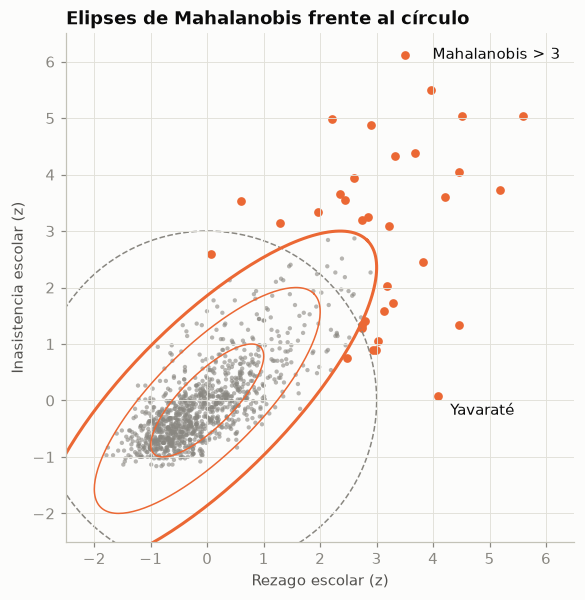

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
fuera = df.mah2 > 3
ax.scatter(Z2[~fuera, 0], Z2[~fuera, 1], s=8, color=GRIS, alpha=.6, edgecolor='none')
ax.scatter(Z2[fuera, 0], Z2[fuera, 1], s=22, color=NARANJA, label='Mahalanobis > 3')
r = np.corrcoef(Z2.T)[0, 1]; t = np.linspace(0, 2 * np.pi, 200)
for k in [1, 2, 3]:
    e = np.c_[np.cos(t) * k * np.sqrt(1 + r), np.sin(t) * k * np.sqrt(1 - r)] @ np.array([[1, 1], [-1, 1]]) / np.sqrt(2)
    ax.plot(e[:, 0], e[:, 1], color=NARANJA, lw=1 + (k == 3))
ax.add_patch(plt.Circle((0, 0), 3, fill=False, ls='--', color=GRIS))
i = df.index[df.municipio == 'Yavaraté'][0]; ax.annotate('Yavaraté', Z2[i], xytext=(8, -12), textcoords='offset points')
ax.set(xlim=(-2.5, 6.5), ylim=(-2.5, 6.5), aspect='equal', xlabel='Rezago escolar (z)', ylabel='Inasistencia escolar (z)', title='Elipses de Mahalanobis frente al círculo'); ax.legend()
plt.show()

Rezago e inasistencia escolar se mueven juntas (r = 0,785), así que las curvas de igual distancia son elipses inclinadas, no círculos. 36 municipios quedan fuera de la elipse de 3; 2 de ellos estaban dentro del círculo de radio 3, es decir, solo son raros por la combinación. Yavaraté (Vaupés) es el ejemplo: 50,5 % de rezago escolar pero solo 5,4 % de inasistencia, contra la tendencia de la nube.

In [7]:
# con las 15 privaciones; si los datos fueran normales, d² seguiría una chi cuadrado con 15 grados de libertad
df['mah15'] = np.sqrt(EmpiricalCovariance().fit(Z).mahalanobis(Z))
corte = np.sqrt(chi2.ppf(.999, df=15))
print(f'Corte chi cuadrado al 99,9 %: {corte:.2f} → {(df.mah15 > corte).sum()} municipios por encima (con datos normales serían ~1)')
df.nlargest(10, 'mah15')[['municipio', 'departamento', 'ipm', 'mah15']]

Corte chi cuadrado al 99,9 %: 6.14 → 58 municipios por encima (con datos normales serían ~1)


,municipio,departamento,ipm,mah15
1114,Pacoa,Vaupés,98.400,15.897
1106,Pana Pana,Guainía,98.500,14.182
1093,Mirití - Paraná,Amazonas,91.200,13.337
1092,La Victoria,Amazonas,96.400,12.828
1100,Barrancominas,Guainía,86.500,10.744
1104,La Guadalupe,Guainía,84.100,10.570
1097,Puerto Santander,Amazonas,88.700,10.133
1107,Morichal,Guainía,95.700,10.023
1117,Yavaraté,Vaupés,94.800,10.018
472,Chaguaní,Cundinamarca,58.700,9.910


Con las 15 privaciones, los más lejanos son municipios de la Amazonía y la Orinoquía con IPM entre 84 % y 99 % (Pacoa, Pana Pana, Mirití-Paraná, La Victoria…): **casos extremos reales, no errores**. Si los datos fueran normales, el corte de la chi cuadrado al 99,9 % dejaría por encima a un solo municipio; aquí quedan 58: las privaciones tienen colas largas, y el corte teórico no sirve como regla automática.

## 4. Aislar: Isolation Forest

Cada árbol corta los datos al azar (una variable y un valor) hasta dejar solo a cada municipio. Lo raro se aísla con pocos cortes. El puntaje promedia la profundidad en 100 árboles.

In [8]:
iso = IsolationForest(n_estimators=100, max_samples=256, random_state=SEMILLA).fit(Z)
df['iforest'] = -iso.score_samples(Z)            # entre 0 y 1: más alto, más fácil de aislar
df.nlargest(10, 'iforest')[['municipio', 'departamento', 'ipm', 'iforest']]

,municipio,departamento,ipm,iforest
1114,Pacoa,Vaupés,98.400,0.779
1106,Pana Pana,Guainía,98.500,0.747
1092,La Victoria,Amazonas,96.400,0.744
1107,Morichal,Guainía,95.700,0.719
653,Uribia,La Guajira,92.200,0.712
1103,Puerto Colombia,Guainía,96.300,0.710
1121,Cumaribo,Vichada,91.400,0.688
1091,La Pedrera,Amazonas,90.900,0.684
1093,Mirití - Paraná,Amazonas,91.200,0.680
1105,Cacahual,Guainía,90.100,0.670


Los diez más fáciles de aislar son casi los mismos de Mahalanobis: Pacoa (0,779), Pana Pana, La Victoria, Morichal… y aparece Uribia (La Guajira). Isolation Forest ve sobre todo los **extremos globales**: los municipios con más privación del país.

## 5. Densidad local: LOF

LOF (*Local Outlier Factor*, factor local de anomalía) compara la densidad de cada municipio con la de sus 20 vecinos más cercanos: cerca de 1, tan denso como ellos; mayor que 1, más aislado que sus vecinos.

In [9]:
lof = LocalOutlierFactor(n_neighbors=20).fit(Z)
df['lof'] = -lof.negative_outlier_factor_         # cerca de 1: normal; mayor: menos denso que sus vecinos
df.nlargest(10, 'lof')[['municipio', 'departamento', 'ipm', 'lof']]

,municipio,departamento,ipm,lof
1086,San Andrés,"Archipiélago De San Andrés, Providencia Y Sant...",16.800,2.888
1087,Providencia,"Archipiélago De San Andrés, Providencia Y Sant...",13.700,2.852
472,Chaguaní,Cundinamarca,58.700,2.390
456,Tuchín,Córdoba,78.000,1.961
935,Colosó,Sucre,59.600,1.824
809,San Calixto,Norte De Santander,73.500,1.815
1114,Pacoa,Vaupés,98.400,1.788
449,San Andrés De Sotavento,Córdoba,76.300,1.768
1105,Cacahual,Guainía,90.100,1.758
796,Herrán,Norte De Santander,52.400,1.669


LOF cuenta otra historia: los dos primeros son **San Andrés y Providencia** (LOF 2,89 y 2,85), con IPM bajo (17 % y 14 %). No son pobres extremos: su mezcla de privaciones no se parece a la de ningún grupo de municipios continentales. Siguen Chaguaní, Tuchín, Colosó y San Calixto. Son **anomalías locales**.

## 6. Comparar los métodos

In [10]:
metodos = ['mah15', 'iforest', 'lof']
marcas = pd.DataFrame({m: df[m].rank(ascending=False) <= N_REV for m in metodos})
comun = pd.DataFrame({a: [(marcas[a] & marcas[b]).sum() for b in metodos] for a in metodos}, index=metodos)
print(f'Municipios en el {N_REV}-superior de cada método que también están en el de otro:'); display(comun)
print('Correlación de rangos (Spearman) entre puntajes:'); display(df[metodos].corr('spearman'))
print(f'Señalados por al menos un método: {marcas.any(axis=1).sum()} · por los tres: {marcas.all(axis=1).sum()}')

Municipios en el 34-superior de cada método que también están en el de otro:


,mah15,iforest,lof
mah15,34,28,13
iforest,28,34,11
lof,13,11,34


Correlación de rangos (Spearman) entre puntajes:


,mah15,iforest,lof
mah15,1.000,0.847,0.696
iforest,0.847,1.000,0.585
lof,0.696,0.585,1.000


Señalados por al menos un método: 61 · por los tres: 11


Mahalanobis e Isolation Forest comparten 28 de sus 34 municipios (correlación de rangos 0,847): ven lo mismo. LOF comparte solo 13 con Mahalanobis y 11 con Isolation Forest (0,585). En total, 61 municipios están en el 3 % de al menos un método y solo 11 en el de los tres. **Use más de un método**: cada uno define «raro» de otra forma.

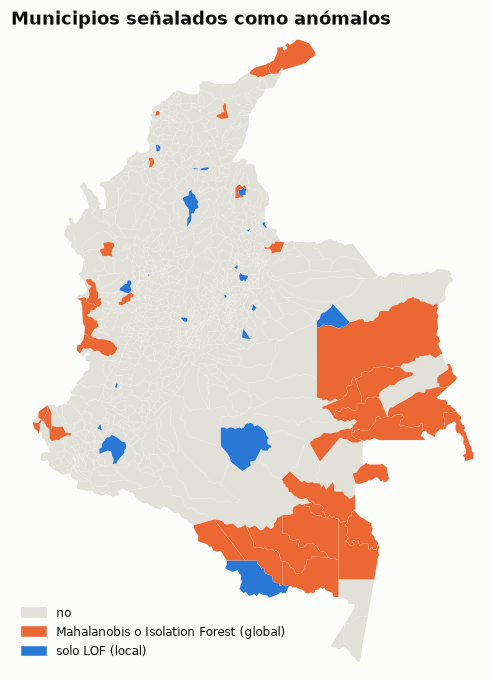

señalado
no                                         1061
Mahalanobis o Isolation Forest (global)      38
solo LOF (local)                             23
Name: count, dtype: int64

In [11]:
df['señalado'] = np.select([marcas.lof & ~marcas.iforest, marcas.iforest | marcas.mah15], ['solo LOF (local)', 'Mahalanobis o Isolation Forest (global)'], 'no')
mapa = gpd.read_file(DATOS / 'municipios_colombia.geojson').merge(df[['cod_mpio', 'señalado']], on='cod_mpio', how='left')
colores = {'no': '#e1e0d9', 'Mahalanobis o Isolation Forest (global)': NARANJA, 'solo LOF (local)': AZUL}
fig, ax = plt.subplots(figsize=(6.5, 7.5))
for k, col in colores.items():
    mapa[mapa.señalado == k].plot(ax=ax, color=col, linewidth=0.05, edgecolor='white')
ax.legend(handles=[mpl.patches.Patch(color=c, label=k) for k, c in colores.items()], loc='lower left', fontsize=8)
ax.set_title('Municipios señalados como anómalos'); encuadre(ax)
plt.show()
df.señalado.value_counts()

Los señalados por los métodos globales (naranja) se concentran en la Amazonía, la Orinoquía, el Pacífico y La Guajira; los que solo señala LOF (azul) aparecen salpicados por todo el país, en la zona andina, el Caribe y también en la Amazonía, junto a vecinos muy distintos. San Andrés y Providencia quedan fuera del recuadro del mapa.

## 7. Evaluar con errores sembrados

Con datos reales nadie sabe cuáles son las anomalías. Para medir, se hace un **ejemplo de juguete**: en una copia de la base se dañan 30 datos de 30 municipios con errores típicos de digitación, y se mira cuántos encuentra cada método.

In [12]:
# Errores de digitación sembrados a propósito en una copia (ejemplo de juguete)
r = np.random.default_rng(7)
X = df[PRIV].to_numpy().copy()
malos = r.choice(len(X), 30, replace=False)
registro = []
for q, i in enumerate(malos):
    v = r.integers(len(PRIV)); a = X[i, v]; tipo = q % 3
    if tipo == 0:   b = a * 10 if a * 10 <= 100 else a / 10                       # coma corrida
    elif tipo == 1: e = int(a); s = f'{e:02d}'; b = int(s[::-1]) + (a - e)       # dígitos invertidos
    else:           b = a / 10 if a >= 10 else a * 10                              # un cero de más o de menos
    X[i, v] = round(b, 1); registro.append((df.municipio[i], PRIV[v], a, X[i, v], ['coma corrida', 'dígitos invertidos', 'un cero de más o de menos'][tipo]))
es_error = np.isin(np.arange(len(X)), malos)
pd.DataFrame(registro, columns=['municipio', 'variable', 'antes', 'después', 'tipo']).head(8)

,municipio,variable,antes,después,tipo
0,Tununguá,inasistencia_escolar,3.600,36.000,coma corrida
1,Úmbita,barreras_acceso_salud,1.900,10.900,dígitos invertidos
2,Mercaderes,inasistencia_escolar,3.500,35.000,un cero de más o de menos
3,San José De Miranda,hacinamiento_critico,12.700,1.300,coma corrida
4,Ataco,barreras_acceso_salud,6.300,60.300,dígitos invertidos
5,Jericó,trabajo_informal,80.000,8.000,un cero de más o de menos
6,San Sebastián De Mariquita,analfabetismo,11.600,1.200,coma corrida
7,Risaralda,bajo_logro_educativo,78.100,87.100,dígitos invertidos


In [13]:
Zs = StandardScaler().fit_transform(X)
punt = {'z (la más extrema)': np.abs(Zs).max(axis=1),
        'Mahalanobis': np.sqrt(EmpiricalCovariance().fit(Zs).mahalanobis(Zs)),
        'Isolation Forest': -IsolationForest(random_state=SEMILLA).fit(Zs).score_samples(Zs),
        'LOF': -LocalOutlierFactor(20).fit(Zs).negative_outlier_factor_}
def hallados(s, n):
    return es_error[np.argsort(-s)[:n]].sum()
tabla = pd.DataFrame({m: {'errores hallados': hallados(s, N_REV), 'sensibilidad': hallados(s, N_REV) / 30, 'precisión': hallados(s, N_REV) / N_REV}
                      for m, s in punt.items()}).T
print(f'Revisando los {N_REV} más raros de cada método (30 errores sembrados):'); tabla

Revisando los 34 más raros de cada método (30 errores sembrados):


,errores hallados,sensibilidad,precisión
z (la más extrema),13.000,0.433,0.382
Mahalanobis,16.000,0.533,0.471
Isolation Forest,0.000,0.000,0.000
LOF,18.000,0.600,0.529


Revisando los 34 más raros de cada método:

- **LOF** encuentra 18 de los 30 errores (sensibilidad 60 %, precisión 53 %).
- **Mahalanobis**, 16 (53 % y 47 %).
- **z** de la variable más extrema, 13 (43 % y 38 %).
- **Isolation Forest**, ninguno: su 3 % más raro sigue ocupado por la pobreza extrema real, que es rara pero no es un error.

**Precisión:** de los señalados, cuántos son errores. **Sensibilidad:** de los errores, cuántos se encontraron. Los métodos que miran la combinación de valores (Mahalanobis, LOF) detectan mejor un dato que no cuadra con el resto del municipio. *(La clase, en el navegador, siembra los errores con otro sorteo y obtiene cifras parecidas: 17, 15, 12 y 2.)*

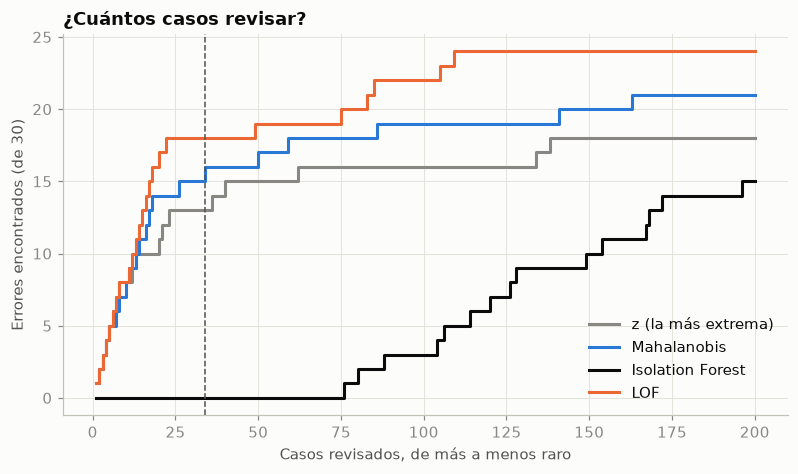

{'z (la más extrema)': np.int64(16), 'Mahalanobis': np.int64(19), 'Isolation Forest': np.int64(3), 'LOF': np.int64(22)} ← revisando 100


In [14]:
ns = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for (m, s), col in zip(punt.items(), [GRIS, AZUL, TINTA, NARANJA]):
    ax.step(ns, [hallados(s, n) for n in ns], where='post', color=col, label=m)
ax.axvline(N_REV, color=TINTA2, ls='--', lw=1)
ax.set(xlabel='Casos revisados, de más a menos raro', ylabel='Errores encontrados (de 30)', title='¿Cuántos casos revisar?'); ax.legend()
plt.show()
print({m: hallados(s, 100) for m, s in punt.items()}, '← revisando 100')

Revisar más casos encuentra más errores, pero cada vez menos por caso revisado: con 100 revisiones, LOF llega a 22 de 30, Mahalanobis a 19, z a 16 e Isolation Forest a 3. Algunos errores nunca se ven, porque cambian poco el dato (un 16 % que se vuelve 1,6 % en una privación que ya varía mucho). El número a revisar es una decisión de costo: cuánto tiempo hay para volver a la fuente.

## 8. Un puente con PCA

In [15]:
# Puente con la clase de PCA: el error de reconstrucción con 4 componentes
pca = PCA(4).fit(Zs)
err = ((Zs - pca.inverse_transform(pca.transform(Zs))) ** 2).sum(axis=1)
print(f'Error de reconstrucción (4 componentes): {hallados(err, N_REV)} de 30 errores entre los {N_REV} primeros')

Error de reconstrucción (4 componentes): 13 de 30 errores entre los 34 primeros


Otra forma de buscar anomalías: reconstruir cada municipio con 4 componentes principales y medir cuánto se equivoca la reconstrucción. Encuentra 13 de los 30 errores entre los 34 primeros, menos que LOF y Mahalanobis: un error de digitación en una sola privación a veces cabe dentro de lo que las componentes explican.

## Conclusiones

1. **Raro no es error.** Los más raros por Mahalanobis e Isolation Forest son municipios de la Amazonía y la Orinoquía con IPM de hasta 99 %: casos extremos reales.
2. **La regla importa:** en una sola variable, z > 3 señala 22 municipios y la caja 63.
3. **Varias variables:** Mahalanobis detecta lo raro por la combinación (Yavaraté), y 36 municipios quedan fuera de la elipse de 3.
4. **Global frente a local:** Mahalanobis e Isolation Forest coinciden en 28 de 34; LOF ve otra cosa (San Andrés, Providencia).
5. **Con errores sembrados**, LOF encuentra 18 de 30 y Mahalanobis 16 en el 3 % revisado; Isolation Forest ninguno, porque su lista la ocupan los extremos reales.
6. **Decidir:** revisar la fuente, corregir los errores, conservar los extremos reales (y analizar con y sin ellos) y reportar siempre qué se excluyó y por qué.

## Retos

1. **Otro k.** Cambie el número de vecinos de LOF (5, 50, 100). ¿Siguen San Andrés y Providencia arriba? ¿Cambian los errores encontrados?
2. **Contaminación.** Use `IsolationForest(contamination=0.03)` y `fit_predict`. ¿Coinciden sus 34 con los del puntaje? ¿Qué decide ese parámetro?
3. **Más errores.** Siembre 100 errores en lugar de 30, o solo de un tipo (coma corrida). ¿Qué método gana en cada caso?
4. **Sin los extremos.** Quite los 20 municipios con más Mahalanobis, vuelva a escalar y repita la evaluación. ¿Mejora Isolation Forest? ¿Por qué?
5. **Un caso de estudio.** Elija un municipio que solo señala LOF y compare sus 15 privaciones con las de sus 20 vecinos más cercanos: ¿en qué es distinto?